# Classifying Ants vs Bees using Transfer Learning in PyTorch

This notebook demonstrates how to perform binary image classification (Ants vs. Bees) using the **Hymenoptera** dataset. We leverage **Transfer Learning** using two popular pre-trained models from `torchvision`:
1. **ResNet18**
2. **EfficientNet-B0**

### Repository
This work is part of the [DeepLearning with PyTorch](https://github.com/ShivaUlavi/DeepLearning_with_PyTorch) repository.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
import time
import os
import copy

## 1. Data Transforms and Augmentation
We define transformations to perform data augmentation on the training set (to prevent overfitting) and normalize both the training and validation images using the standard ImageNet channel statistics.

In [ ]:
mean = np.array([0.5, 0.5, 0.5])
std = np.array([0.25, 0.25, 0.25])

data_transforms = {
    'train' : transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ]),

    'val' : transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ]),
}

## 2. Load Dataset
We use `ImageFolder` to structured directories into PyTorch datasets, configure `DataLoaders` for batching, and extract target class names.

In [ ]:
data_dir = "./data/hymenoptera_data/"

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}

dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=32,
                                             shuffle=True, num_workers=0)
              for x in ['train', 'val']}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}

class_names = image_datasets['train'].classes

## 3. Configure Compute Device
Ensure GPU acceleration is utilized if available.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"device = {device} & class names = {class_names}")

device = cuda & class names = ['ants', 'bees']


## 4. Visualize Sample Images
Let's plot a batch of training images to observe the data augmentations and labels.

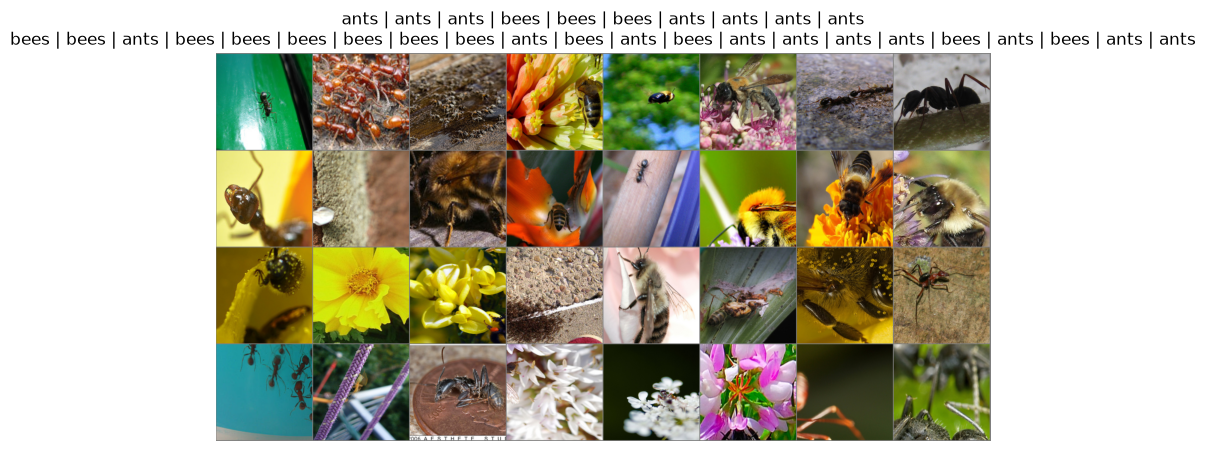

In [ ]:
def imshow(inp, title=None):
    inp = inp.cpu().numpy() if inp.is_cuda else inp.numpy()
    inp = inp.transpose((1, 2, 0))
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.figure(figsize=(10, 10))
    plt.imshow(inp)

    if title:
        plt.title(title)

    plt.axis('off')  # Removes the axis ticks and borders
    plt.show()

inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs)

names_list = [class_names[x] for x in classes]
formatted_title = " | ".join(names_list[:10]) + "\n" + " | ".join(names_list[10:])

imshow(out, title=formatted_title)


## 5. Training Loop Helper Function
This helper function handles the training and validation phases, step-down learning rate scheduling, and tracks the best model weights across all epochs.

In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        for phase in ['train','val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0.0

            for inputs,labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                #forward pass, track history if it is 'train' phase
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()

                #statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print("{} Loss: {:.4f} Acc: {:.4f}".format(phase, epoch_loss, epoch_acc))

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

## 6. Model 1: ResNet18 (Feature Extractor)
We freeze all convolutional layers of ResNet18 and replace the final fully-connected layer to output 2 class scores.

In [ ]:
model_conv = torchvision.models.resnet18(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False  ## freezes the parameters so that the gradients are not computed in backward()

num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# only parameters of final layer will be optimized
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 10 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=10, gamma=0.1)

model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=100)

C:\Users\Shivachetan Ulavi\Anaconda3\envs\torch_env\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Shivachetan Ulavi\Anaconda3\envs\torch_env\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 0/99
----------
train Loss: 0.6782 Acc: 0.5943
val Loss: 0.5992 Acc: 0.6797

Epoch 1/99
----------
train Loss: 0.5378 Acc: 0.7541
val Loss: 0.4471 Acc: 0.8431

Epoch 2/99
----------
train Loss: 0.4607 Acc: 0.7992
val Loss: 0.3389 Acc: 0.8889

Epoch 3/99
----------
train Loss: 0.3356 Acc: 0.8648
val Loss: 0.2925 Acc: 0.9150

Epoch 4/99
----------
train Loss: 0.2955 Acc: 0.8975
val Loss: 0.2578 Acc: 0.9281

Epoch 5/99
----------
train Loss: 0.2843 Acc: 0.8852
val Loss: 0.2360 Acc: 0.9412

Epoch 6/99
----------
train Loss: 0.2379 Acc: 0.9262
val Loss: 0.2178 Acc: 0.9412

Epoch 7/99
----------
train Loss: 0.2515 Acc: 0.9016
val Loss: 0.2137 Acc: 0.9346

Epoch 8/99
----------
train Loss: 0.2267 Acc: 0.9098
val Loss: 0.2026 Acc: 0.9542

Epoch 9/99
----------
train Loss: 0.2130 Acc: 0.9098
val Loss: 0.2029 Acc: 0.9412

Epoch 10/99
----------
train Loss: 0.2497 Acc: 0.9016
val Loss: 0.2042 Acc: 0.9412

Epoch 11/99
----------
train Loss: 0.1898 Acc: 0.9098
val Loss: 0.2080 Acc: 0.9412

Ep

## 7. Model 2: EfficientNet-B0 (Feature Extractor)
Similarly, we freeze the backbone parameters of EfficientNet-B0 and adjust its classifier head to match our 2 target classes.

In [ ]:
#EfficientNet-B0
model_conv2 = torchvision.models.efficientnet_b0(pretrained=True)

# 2. Freeze all base parameters
for param in model_conv2.parameters():
  param.requires_grad = False

# 3. Replace the final classifier layer (EfficientNet's classifier is a Sequential block)
num_ftrs = model_conv2.classifier[1].in_features
model_conv2.classifier[1] = nn.Linear(num_ftrs, 2)

# 4. Move to device and configure optimizer for only the classifier parameters
model_conv2 = model_conv2.to(device)
optimizer_conv2 = optim.SGD(
    model_conv2.classifier.parameters(), lr=0.001, momentum=0.9
)

exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv2, step_size=10, gamma=0.1)

model_conv2 = train_model(model_conv2, criterion, optimizer_conv2,
                         exp_lr_scheduler, num_epochs=100)


C:\Users\Shivachetan Ulavi\Anaconda3\envs\torch_env\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Shivachetan Ulavi\Anaconda3\envs\torch_env\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Shivachetan Ulavi/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:01<00:00, 11.2MB/s]


Epoch 0/99
----------
train Loss: 0.6805 Acc: 0.5369
val Loss: 0.6171 Acc: 0.7320

Epoch 1/99
----------
train Loss: 0.6264 Acc: 0.6967
val Loss: 0.5439 Acc: 0.8301

Epoch 2/99
----------
train Loss: 0.5617 Acc: 0.8074
val Loss: 0.4863 Acc: 0.8627

Epoch 3/99
----------
train Loss: 0.5124 Acc: 0.8197
val Loss: 0.4372 Acc: 0.9020

Epoch 4/99
----------
train Loss: 0.4521 Acc: 0.8934
val Loss: 0.4000 Acc: 0.9150

Epoch 5/99
----------
train Loss: 0.4391 Acc: 0.8811
val Loss: 0.3655 Acc: 0.9412

Epoch 6/99
----------
train Loss: 0.3970 Acc: 0.8975
val Loss: 0.3403 Acc: 0.9346

Epoch 7/99
----------
train Loss: 0.3879 Acc: 0.8811
val Loss: 0.3210 Acc: 0.9477

Epoch 8/99
----------
train Loss: 0.3489 Acc: 0.9180
val Loss: 0.3070 Acc: 0.9412

Epoch 9/99
----------
train Loss: 0.3590 Acc: 0.9057
val Loss: 0.2958 Acc: 0.9477

Epoch 10/99
----------
train Loss: 0.3583 Acc: 0.9016
val Loss: 0.2911 Acc: 0.9477

Epoch 11/99
----------
train Loss: 0.3368 Acc: 0.9221
val Loss: 0.2905 Acc: 0.9412

Ep

## 8. Conclusion and Model Comparison

Both models were trained using transfer learning as fixed feature extractors over 100 epochs on the Hymenoptera dataset:

* **ResNet18** achieved a peak validation accuracy of **95.42%** in approximately **6 minutes and 44 seconds**.
* **EfficientNet-B0** achieved a peak validation accuracy of **95.42%** in approximately **7 minutes and 33 seconds**.

### Key Takeaways:
1. **High Efficiency**: Transfer learning allowed us to reach over 95% classification accuracy on a very small dataset in just a few minutes of training.
2. **Freezing Feature Extractors**: Because we froze the convolutional layers and only optimized the final linear classifiers, we successfully mitigated overfitting while keeping training speeds extremely fast.
3. **Model Selection**: While both models yielded identical best validation accuracies (95.42%), ResNet18 completed training slightly quicker on this setup.